### Task 0

Print Hello world to the terminal 

In [ ]:
# Put your solution in this box and run the program

### Task 1 - Load an Image

Load in the "shapes.png" image and display it using matplotlib. 

Ensure the colours are correctly displayed in RGB. [Hint](https://docs.opencv.org/4.x/d8/d01/group__imgproc__color__conversions.html#ga4e0972be5de079fed4e3a10e24ef5ef0) 

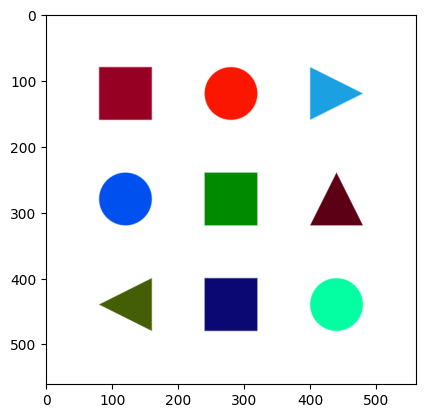

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_FILE = "shapes.png"

image = cv2.imread(IMAGE_FILE)

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB);

plt.imshow(image_rgb)

### Task 2 - Colour Mask

Using a blue color mask, generate a monochrome mask of the blue shapes. 

You will need to use the cv2.inRange() function. 

Hint: ([0,0,90] and [150,180,255])






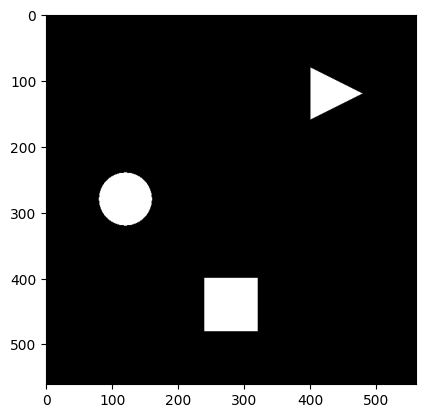

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_FILE = "shapes.png"

lower_blue = np.array([90, 0, 0], dtype=np.uint8)
upper_blue = np.array([255, 180, 150], dtype=np.uint8)

blue_mask = cv2.inRange(image, lower_blue, upper_blue)


plt.imshow(blue_mask, cmap = 'gray');




### Task 3 - Bitwise Operation

Using the bitwise and operation, apply the mask to the source image and display the result. 

Examples for cv2.bitwise_and can be found [Here](https://www.geeksforgeeks.org/arithmetic-operations-on-images-using-opencv-set-2-bitwise-operations-on-binary-images/) 

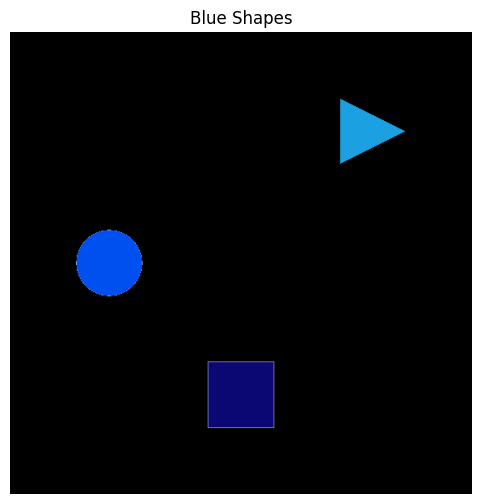

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
result = cv2.bitwise_and(image, image, mask=blue_mask)

# Convert to RGB for displaying
result_rgb = cv2.cvtColor(result, cv2.COLOR_BGR2RGB)

# Display the result
plt.figure(figsize=(6,6))
plt.imshow(result_rgb)
plt.title("Blue Shapes")
plt.axis("off")
plt.show()

### Task 4 - HSV and Maze

HSV (Hue, Saturation, Value) may provide better results for the Micromouse maze. 

Use the provided "hsv_picker.ipynb" to find a good range of HSV values for the maze and display the resulting mask of the maze walls. 

In [ ]:
import cv2
import numpy as np

# Global HSV variables
H_low = 0
H_high = 179;
S_low = 0
S_high = 255
V_low = 0
V_high = 255


# Trackbar callback
def callback(x):
    global H_low, H_high, S_low, S_high, V_low, V_high
    
    H_low = cv2.getTrackbarPos('low H', 'controls')
    H_high = cv2.getTrackbarPos('high H', 'controls')
    S_low = cv2.getTrackbarPos('low S', 'controls')
    S_high = cv2.getTrackbarPos('high S', 'controls')
    V_low = cv2.getTrackbarPos('low V', 'controls')
    V_high = cv2.getTrackbarPos('high V', 'controls')


# Create control window
cv2.namedWindow("controls")
cv2.resizeWindow("controls", 550, 300)


# Create sliders
cv2.createTrackbar('low H','controls',0,179,callback)
cv2.createTrackbar('high H','controls',179,179,callback)

cv2.createTrackbar('low S','controls',0,255,callback)
cv2.createTrackbar('high S','controls',255,255,callback)

cv2.createTrackbar('low V','controls',0,255,callback)
cv2.createTrackbar('high V','controls',255,255,callback)


# Load image
img = cv2.imread("maze.jpg")

if img is None:
    print("Cannot find maze.jpg")
    exit()


# Resize image
width = img.shape[1]//4
height = img.shape[0]//4
img = cv2.resize(img,(width,height))


# Convert to HSV
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)


while True:

    # HSV range
    hsv_low = np.array([H_low, S_low, V_low])
    hsv_high = np.array([H_high, S_high, V_high])


    # Create mask
    mask = cv2.inRange(hsv, hsv_low, hsv_high)


    # Display
    cv2.imshow("Original", img)
    cv2.imshow("Mask", mask)


    # ESC key
    if cv2.waitKey(1) & 0xFF == 27:
        break


cv2.destroyAllWindows()


### Task 5 - Erode

Perform an erode operation from the source image. Use a kernel size of 7 and perform 5 iterations. 

Image loaded: (1582, 2374, 3)


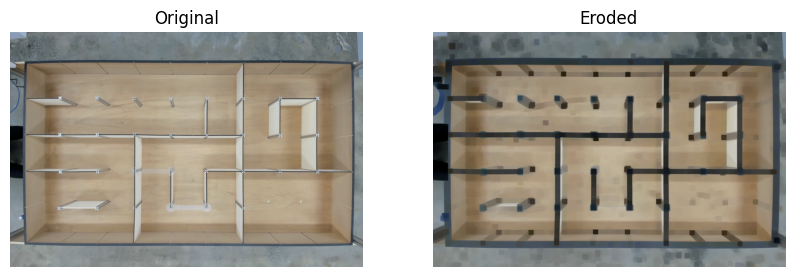

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_FILE = "maze.jpg"

# Load image
img = cv2.imread(IMAGE_FILE)

# Check image
if img is None:
    print("ERROR: Cannot find maze.jpg")
else:
    print("Image loaded:", img.shape)

    # Create kernel (7x7)
    kernel = np.ones((7,7), np.uint8)

    # Erode image
    eroded = cv2.erode(img, kernel, iterations=5)

    # Convert BGR to RGB
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    eroded_rgb = cv2.cvtColor(eroded, cv2.COLOR_BGR2RGB)

    # Display
    plt.figure(figsize=(10,5))

    plt.subplot(1,2,1)
    plt.imshow(img_rgb)
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1,2,2)
    plt.imshow(eroded_rgb)
    plt.title("Eroded")
    plt.axis("off")

    plt.show()


### Task 6 - Dilate

Perform an dilate operation from the source image. Use a kernel size of 3 and perform 5 iterations. 

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_FILE = "maze.jpg"



### Task 7 - ASCII representation

Note: This task should be completed as it is part of the Micromouse assignment

Convert the maze into an ASCII representation shown in the lab document. You may need to perform a series of erosions and dilations to get a good mask. 

Hint: Write a generic function to sample pixels between two coordinates. 


Image loaded: (1582, 2374, 3)


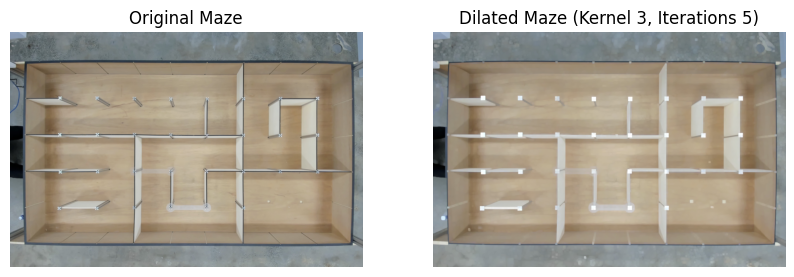

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_FILE = "maze.jpg"

# Load image
img = cv2.imread(IMAGE_FILE)

# Check image loaded
if img is None:
    print("ERROR: Cannot find maze.jpg")
else:
    print("Image loaded:", img.shape)

    # Create 3x3 kernel
    kernel = np.ones((3,3), np.uint8)

    # Perform dilation
    dilated = cv2.dilate(img, kernel, iterations=5)

    # Convert BGR to RGB for matplotlib
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    dilated_rgb = cv2.cvtColor(dilated, cv2.COLOR_BGR2RGB)

    # Display results
    plt.figure(figsize=(10,5))

    plt.subplot(1,2,1)
    plt.imshow(img_rgb)
    plt.title("Original Maze")
    plt.axis("off")

    plt.subplot(1,2,2)
    plt.imshow(dilated_rgb)
    plt.title("Dilated Maze (Kernel 3, Iterations 5)")
    plt.axis("off")

    plt.show()